# FoodWise — Rating Prediction (Supervised ML)

**Goal:** predict a restaurant's rating from catalogue features, so that **unrated** listings get a sensible *estimate* in the ranking instead of a flat 3.5.

**Honest expectation:** ratings are noisy, and the data has no review counts or user data, so the model can only explain a small part of the variation. The goal is to be clearly better than the old guess, not to claim high accuracy.

Steps: 1. Look at the target · 2. Features · 3. Grouped train/test split · 4. Models vs baselines · 5. Feature importance · 6. Predicted vs actual · 7. Estimates for unrated listings

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

sys.path.append("..")
from src.preprocessing import load_raw_data, clean_dataset
from src.ml_model import RatingPredictor, build_features, _boosting

df = clean_dataset(load_raw_data()).reset_index(drop=True)
rated = df[df["rating_numeric"].notna()].reset_index(drop=True)
print(f"{len(df):,} listings | {len(rated):,} rated | {df['rating_numeric'].isna().sum():,} unrated")

44,708 listings | 37,758 rated | 6,950 unrated


## 1. The target: rating
Most ratings sit between 3.5 and 4.5, so predicting the average is already a strong baseline.

count    37758.00
mean         3.92
std          0.35
min          2.40
25%          3.70
50%          4.00
75%          4.20
max          4.90
Name: rating_numeric, dtype: float64


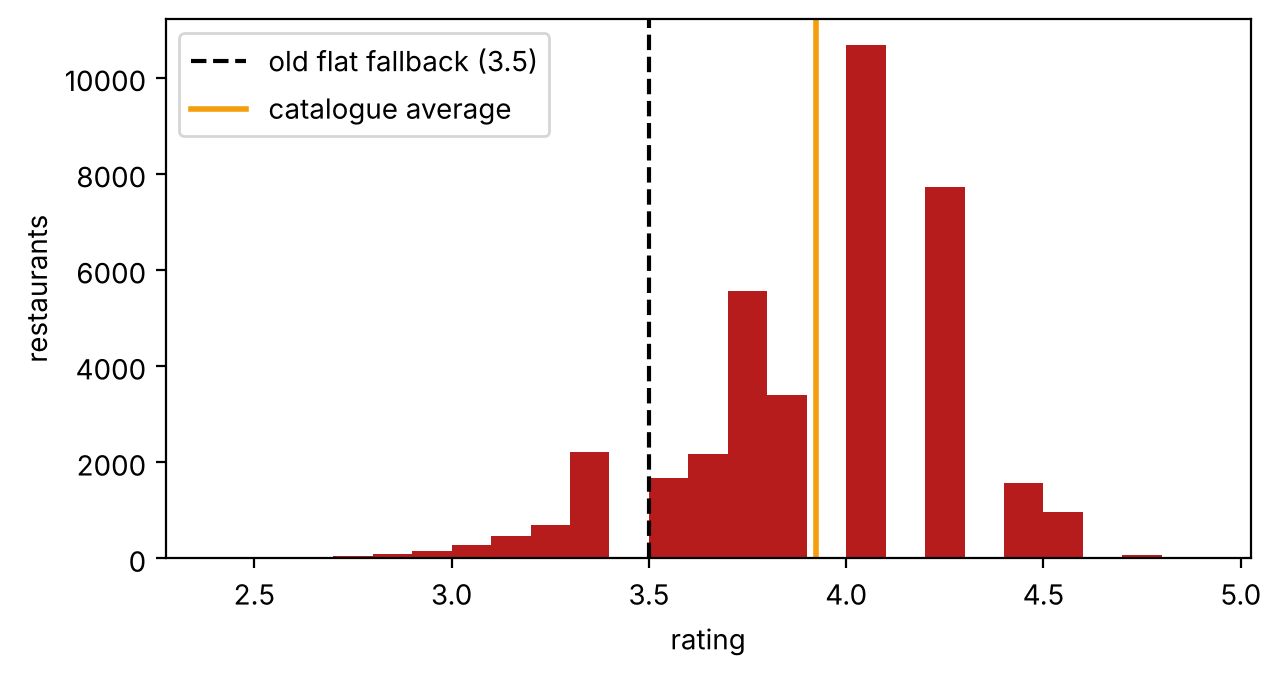

In [2]:
print(rated["rating_numeric"].describe().round(2))
plt.figure(figsize=(7, 3.5))
plt.hist(rated["rating_numeric"], bins=25, color="#B71C1C")
plt.axvline(3.5, color="black", ls="--", label="old flat fallback (3.5)")
plt.axvline(rated["rating_numeric"].mean(), color="#F59E0B", lw=2, label="catalogue average")
plt.xlabel("rating"); plt.ylabel("restaurants"); plt.legend(); plt.show()

## 2. Features
Cuisine tags, city, safety label, price tier, log price, listed delivery time and the veg hint. The **restaurant name and the rating itself are never used as inputs**, so there is no leakage.

In [3]:
X = build_features(rated)
print(X.head(5).to_string())
print("\nMissing values per feature:")
print(X.isna().sum())

                                                           cuisine_text  city                                                 safety_label price_tier  log_price  delivery  veg
0                                Bakery|Fast Food|Pizza|Sandwich|Burger  Agra                      Restaurant partner follows WHO protocol     Budget   3.931826      36.0    0
1                               North Indian|Mughlai|Rolls|Burger|Momos  Agra  Follows all Max Safety measures to ensure your food is safe     Budget   3.931826      22.0    0
2               North Indian|South Indian|Chinese|Fast Food|Street Food  Agra  Follows all Max Safety measures to ensure your food is safe     Budget   3.931826      27.0    0
3  Mithai|Street Food|South Indian|Chinese|Ice Cream|Desserts|Beverages  Agra                      Restaurant partner follows WHO protocol     Budget   3.931826      28.0    0
4                                            Burger|Fast Food|Beverages  Agra  Follows all Max Safety measures to ensure

## 3. Split that keeps chains together
A chain such as Pizza Hut has many outlets. If some outlets were in training and others in testing, the model could look good by remembering the chain. So all outlets of one name go to the same side.

In [4]:
y = rated["rating_numeric"]
groups = rated["Restaurant Name"].str.lower().str.strip()
train, test = next(GroupShuffleSplit(1, test_size=0.2, random_state=42).split(X, y, groups))
print(f"train: {len(train):,} rows | test: {len(test):,} rows")
print("Names in both sets:", len(set(groups.iloc[train]) & set(groups.iloc[test])))

train: 30,310 rows | test: 7,448 rows
Names in both sets: 0


## 4. Models vs baselines
MAE and RMSE are in rating points (lower is better). R² = 0 means no better than predicting the average.

In [5]:
predictor = RatingPredictor()
metrics = predictor.evaluate(df)
metrics

,Model,MAE,RMSE,R2
0,Constant 3.5 (old fallback),0.486,0.554,-1.475
1,Predict the average,0.281,0.352,-0.000
2,Ridge regression,0.263,0.333,0.107
3,Gradient boosting (used),0.259,0.327,0.134


**Reading the table:** the old flat 3.5 guess is far off (MAE about 0.49) because the real average is about 3.9. Predicting the average gives MAE about 0.28. The gradient boosting model improves on that to about 0.26 and reaches R² of about 0.13. That is a small but real gain, which is what I expect from noisy ratings and weak features.

## 5. Which features matter
Permutation importance: how much the test error grows when one feature is shuffled.

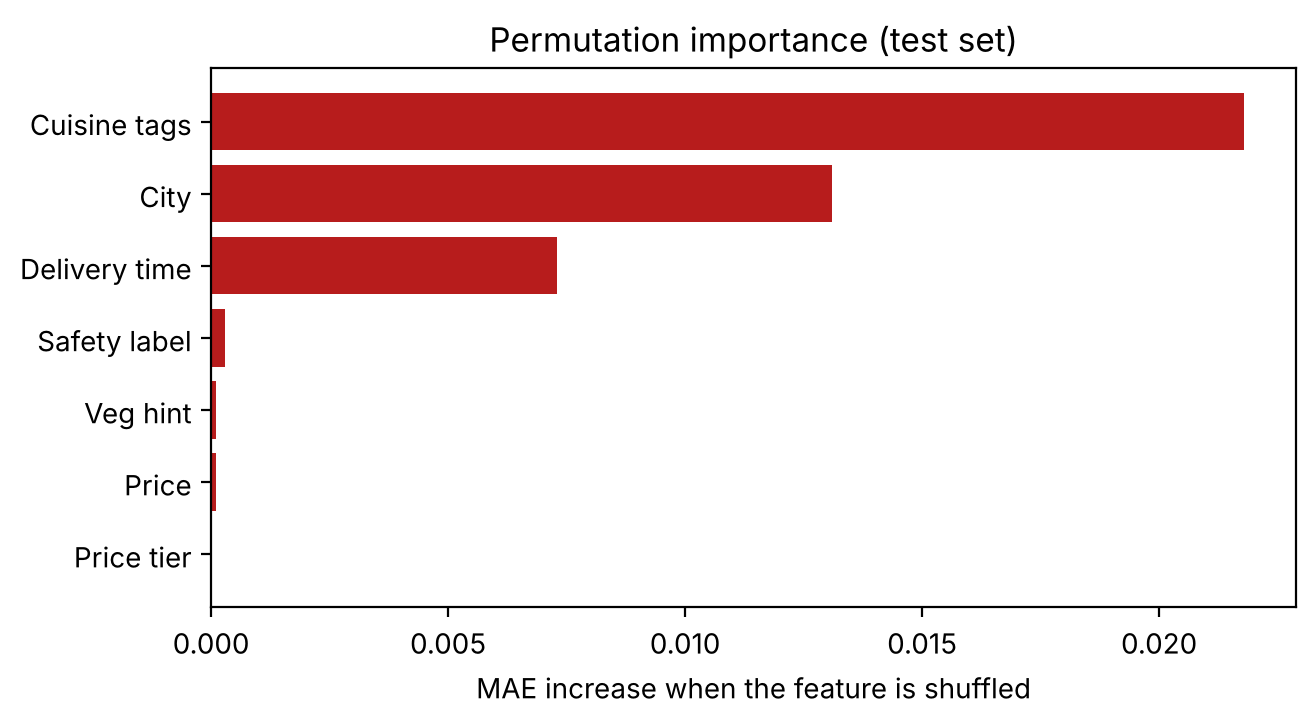

,Feature,MAE increase when shuffled
0,Cuisine tags,0.0218
1,City,0.0131
2,Delivery time,0.0073
3,Safety label,0.0003
4,Price,0.0001
5,Veg hint,0.0001
6,Price tier,0.0000


In [6]:
imp = predictor.importance_.sort_values("MAE increase when shuffled")
plt.figure(figsize=(7, 3.5))
plt.barh(imp["Feature"], imp["MAE increase when shuffled"], color="#B71C1C")
plt.xlabel("MAE increase when the feature is shuffled"); plt.title("Permutation importance (test set)"); plt.show()
predictor.importance_

## 6. Predicted vs actual
Predictions stay in a narrow band around the average: the model is cautious, and cannot tell a 3.0 from a 4.5 restaurant using these features alone.

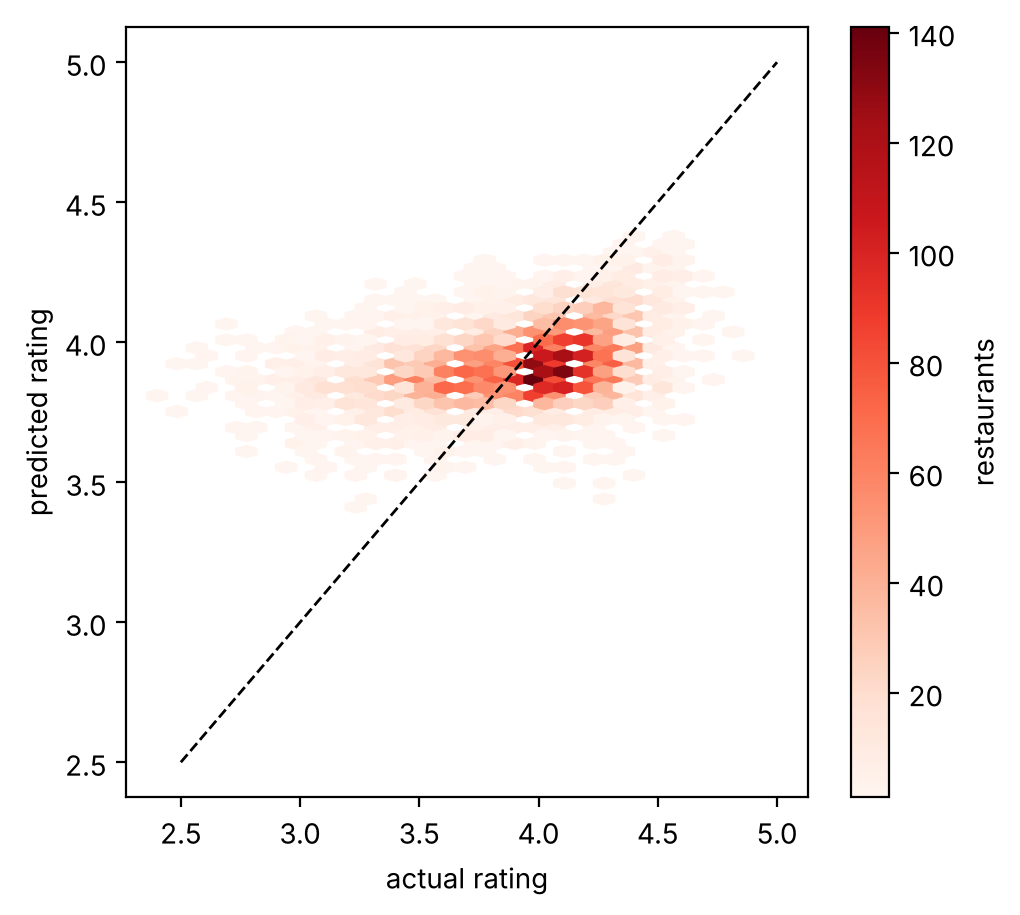

Spread of predictions (std): 0.119 | spread of actual ratings (std): 0.352


In [7]:
model = _boosting(42).fit(X.iloc[train], y.iloc[train])
pred = np.clip(model.predict(X.iloc[test]), 2, 5)
plt.figure(figsize=(5.5, 5))
plt.hexbin(y.iloc[test], pred, gridsize=30, cmap="Reds", mincnt=1)
plt.plot([2.5, 5], [2.5, 5], "k--", lw=1)
plt.xlabel("actual rating"); plt.ylabel("predicted rating"); plt.colorbar(label="restaurants"); plt.show()
print("Spread of predictions (std):", round(pred.std(), 3), "| spread of actual ratings (std):", round(y.iloc[test].std(), 3))

## 7. Estimates for unrated listings
These are used inside the ranking only, and are shown in the app as *estimates*. Unrated listings may differ from rated ones (many are new), so these cannot be validated against real ratings.

count    6950.00
mean        3.88
std         0.10
min         3.44
25%         3.83
50%         3.88
75%         3.95
max         4.35
dtype: float64


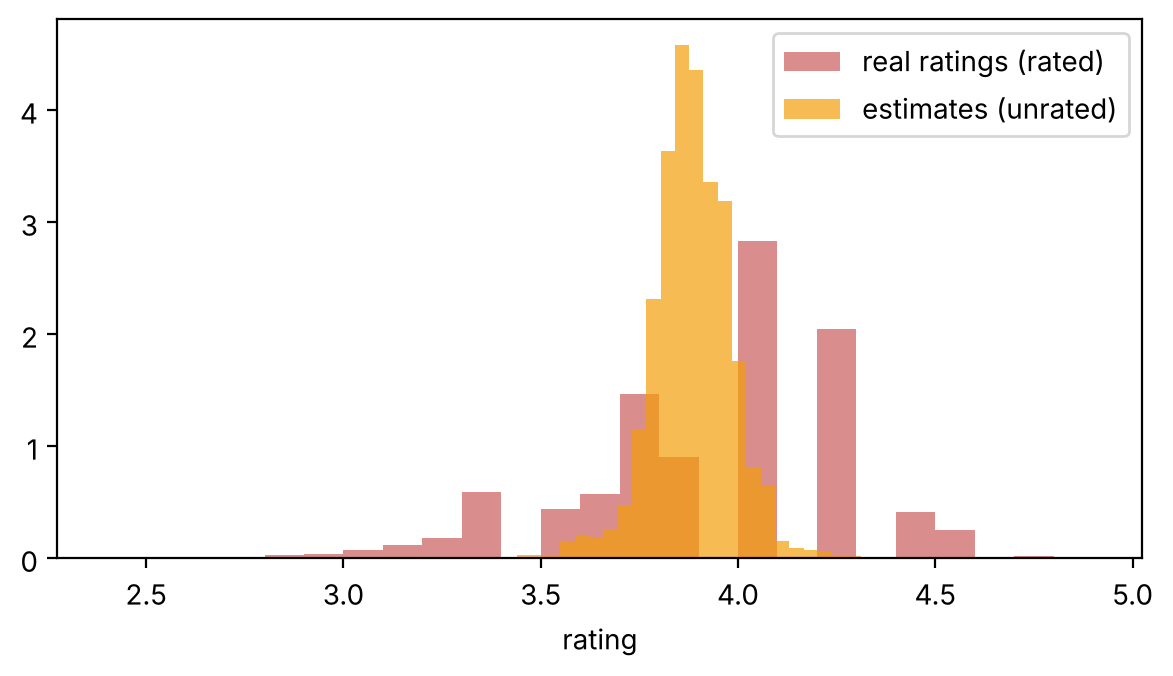

In [8]:
final = RatingPredictor().fit(df)
unrated = df[df["rating_numeric"].isna()]
estimate = final.predict(unrated)
print(pd.Series(estimate).describe().round(2))
plt.figure(figsize=(7, 3.5))
plt.hist(rated["rating_numeric"], bins=25, alpha=.5, density=True, color="#B71C1C", label="real ratings (rated)")
plt.hist(estimate, bins=25, alpha=.7, density=True, color="#F59E0B", label="estimates (unrated)")
plt.xlabel("rating"); plt.legend(); plt.show()

## Conclusion
- A supervised model can estimate ratings only modestly (R² about 0.13) from these features. Cuisine and city matter most.
- It is still much closer to real ratings than the flat 3.5 the ranking used before, so it is a better way to treat unrated listings.
- To do better I would need review counts, dish-level data and user interactions.